# Forecasting the Release of September PCE Inflation Growth
#### - Step 1: Transform the original FRED data to growth rates at annual rates.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np 
from statsmodels.tsa.arima.model import ARIMA
import warnings

plt.rcParams.update({
    "font.size": 8,
    "axes.titlesize": 9,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 6.5,
    "lines.linewidth": 1.2,
})

In [3]:
df = pd.read_csv("PCEPI.csv")
df['observation_date'] = pd.to_datetime(df['observation_date'])
df["Growth"] = 1200*(np.log(df["PCEPI"]) - np.log(df["PCEPI"].shift(1)))
df = df.dropna()
mu = df['Growth'].mean()
df.head


<bound method NDFrame.head of     observation_date    PCEPI    Growth
1         1984-01-01   47.564  5.208495
2         1984-02-01   47.884  8.046296
3         1984-03-01   48.041  3.928072
4         1984-04-01   48.224  4.562411
5         1984-05-01   48.285  1.516957
..               ...      ...       ...
508       2026-04-01  130.672  5.218260
509       2026-05-01  131.241  5.213953
510       2026-06-01  131.106 -1.235006
511       2026-07-01  131.172  0.603939
512       2026-08-01  131.579  3.717591

[512 rows x 3 columns]>

##### Now that the dataframe is transformed to growth at annual rates, we can plot our data with the mean also calculated above.

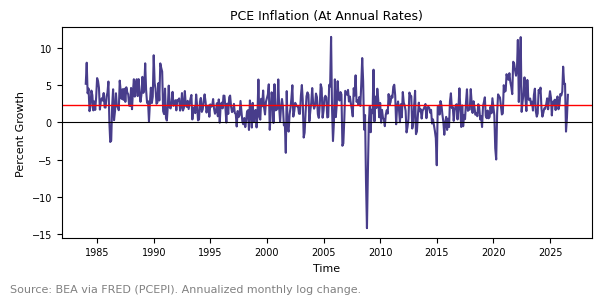

In [4]:
# Setting up plot
fig, ax = plt.subplots(figsize=(6,3))
ax.plot(df['observation_date'], df['Growth'], linewidth = 1.5, color = 'darkslateblue')
ax.axhline(0, color = 'black', linewidth = .8)
ax.axhline(mu, color = 'red', linewidth = 1)
ax.set_title("PCE Inflation (At Annual Rates)")
ax.set_ylabel('Percent Growth')
ax.set_xlabel('Time')

fig.text(0.01, 0.01, "Source: BEA via FRED (PCEPI). Annualized monthly log change.",
         ha="left", va="bottom", fontsize=8, color="gray")
fig.tight_layout(rect=[0, 0.04, 1, 1])
fig.savefig('PCE_Inflation.png', dpi=300)

plt.show()

### Model Selection
#### I will be selecting a pure AR model for this forecast. Given I am working with monthly level data I am going to impose that the order of this model will no more than 6. The selection of which order of AR model to use will be done using AIC/BIC values.

In [8]:
y = df.set_index('observation_date')['Growth'].dropna()
max_p = 6
rows = {}
for p in range(0, max_p + 1):
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            res_p = ARIMA(y.values, order=(p, 0, 0)).fit()
        if p == 0:
            rows['White Noise'] = {"AIC": res_p.aic,
                            "BIC": res_p.bic,
                            "converged": res_p.mle_retvals.get("converged", True)}
        else:
            rows[f"AR({p})"] = {"AIC": res_p.aic,
                            "BIC": res_p.bic,
                            "converged": res_p.mle_retvals.get("converged", True)}
    except Exception as e:
        rows[f"AR({p})"] = {"AIC": None, "BIC": None, "converged": False}

ic_ar = pd.DataFrame(rows).T
ic_ar["AIC"] = ic_ar["AIC"].astype(float).round(2)
ic_ar["BIC"] = ic_ar["BIC"].astype(float).round(2)

print(ic_ar)



                 AIC      BIC converged
White Noise  2334.46  2342.93      True
AR(1)        2201.33  2214.05      True
AR(2)        2203.18  2220.14      True
AR(3)        2198.22  2219.41      True
AR(4)        2197.11  2222.54      True
AR(5)        2198.46  2228.13      True
AR(6)        2198.95  2232.86      True


### BIC clearly points toward an AR(1) being the correct choice of model for this case. AIC seems to decrease until we reach an AR(4) model, but by amounts that seem relatively insignificant given how AIC favors more complex models.

## Fitting the AR(1) Model and Creating the Forecast

In [10]:
y = y.asfreq('MS')
model = ARIMA(y, order = (1,0,0))
res = model.fit()
print(res.summary())

print("The forecast of the next 12 months is:")
forecast = res.get_forecast(steps = 12)
ci90 = forecast.summary_frame(alpha = .1)
ci50 = forecast.summary_frame(alpha=.5)


                               SARIMAX Results                                
Dep. Variable:                 Growth   No. Observations:                  512
Model:                 ARIMA(1, 0, 0)   Log Likelihood               -1097.666
Date:                Wed, 14 Oct 2026   AIC                           2201.333
Time:                        21:24:57   BIC                           2214.048
Sample:                    01-01-1984   HQIC                          2206.317
                         - 08-01-2026                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.4024      0.179     13.450      0.000       2.052       2.753
ar.L1          0.4819      0.026     18.726      0.000       0.431       0.532
sigma2         4.2604      0.183     23.279      0.0

In [ ]:
tbl = pd.DataFrame({
    "Estimate": res.params,
    "Std. error": res.bse,
    "p-value": res.pvalues,
})
tbl.index = ["Mean ($\\mu$)", "AR(1) ($\\phi$)", "$\\sigma^2$"]   # rename rows (order matches res.params)

latex = tbl.to_latex(
    float_format="%.3f",
    column_format="lccc",
    caption="AR(1) estimates for annualized PCE inflation",
    label="tab:ar1",
    escape=False,          # lets the $...$ in the row names render as math
    position="htbp",
)

with open("ar1_table.tex", "w") as f:
    f.write(latex)



In [15]:
fc_table = pd.DataFrame({
    "h": range(1, len(ci90) + 1),
    "Month": ci90.index.strftime("%b %Y"),
    "Forecast": ci90["mean"].values,
    "50% lower": ci50["mean_ci_lower"].values,
    "50% upper": ci50["mean_ci_upper"].values,
    "90% lower": ci90["mean_ci_lower"].values,
    "90% upper": ci90["mean_ci_upper"].values,
})

rows = fc_table.itertuples(index=False)   # columns: h, Month, Forecast, 50 lo, 50 hi, 90 lo, 90 hi

lines = [
    r"\begin{table}[htbp]",
    r"\centering",
    r"\caption{AR(1) forecasts of annualized PCE inflation (percent)}",
    r"\label{tab:forecast}",
    r"\begin{tabular}{clccccc}",
    r"\toprule",
    r" & & & \multicolumn{2}{c}{50\% interval} & \multicolumn{2}{c}{90\% interval} \\",
    r"\cmidrule(lr){4-5} \cmidrule(lr){6-7}",
    r"$h$ & Month & Forecast & Lower & Upper & Lower & Upper \\",
    r"\midrule",
]
for h, month, f, lo50, hi50, lo90, hi90 in rows:
    lines.append(f"{h} & {month} & {f:.2f} & {lo50:.2f} & {hi50:.2f} & {lo90:.2f} & {hi90:.2f} \\\\")
lines += [r"\bottomrule", r"\end{tabular}", r"\end{table}"]

with open("forecast_table.tex", "w") as fh:
    fh.write("\n".join(lines))

### Plotting the Forecast with Forecast Intervals

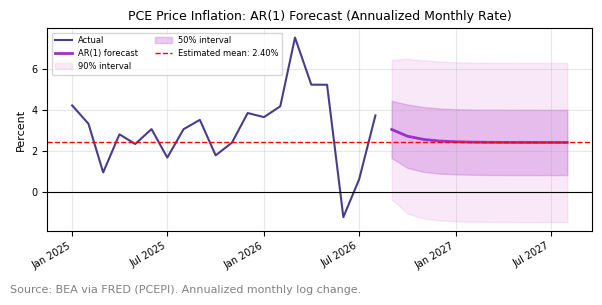

In [11]:
recent = y.loc["2025":]                      # window of history to show, makes the graph easier to understand
point = ci90['mean']

fig, ax = plt.subplots(figsize=(6, 3))

ax.plot(recent.index, recent, color="darkslateblue", linewidth=1.5, label="Actual")
ax.plot(point.index, point, color="darkorchid", linewidth=2, label="AR(1) forecast")

ax.fill_between(ci90.index, ci90["mean_ci_lower"], ci90["mean_ci_upper"],
                color="orchid", alpha=0.15, label="90% interval")
ax.fill_between(ci50.index, ci50["mean_ci_lower"], ci50["mean_ci_upper"],
                color="mediumorchid", alpha=0.30, label="50% interval")

ax.axhline(0, color="black", linewidth=0.8)
ax.axhline(res.params["const"], color="red", linestyle="--", linewidth=1,
           label=f"Estimated mean: {res.params['const']:.2f}%")

ax.set_title("PCE Price Inflation: AR(1) Forecast (Annualized Monthly Rate)")
ax.set_ylabel("Percent")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.grid(alpha=0.3)
ax.legend(loc="upper left", ncol=2,  fontsize=6)
fig.autofmt_xdate()

fig.text(0.01, 0.01, "Source: BEA via FRED (PCEPI). Annualized monthly log change.",
         ha="left", va="bottom", fontsize=8, color="gray")
fig.tight_layout(rect=[0, 0.05, 1, 1])
fig.savefig("ar1_forecast.png", dpi=300)
plt.show()